# Functional data: curves as responses and covariates

A functional observation is a curve: a quantity recorded at many values of a
continuous index, such as time, age or wavelength, for each unit of the study.
The two most common functional regression models can be fitted with
`gamboost`: a curve response explained by scalar covariates (function-on-scalar
regression) and a scalar response explained by a curve (scalar-on-function or
signal regression). mboostrs has no dedicated interface for curves. The models
are written with existing terms: the data are stacked into one row per curve
and index value, effects that vary along the index are tensor products
(`%X%`), a curve covariate enters through a user-defined design (`buser`), and
resampling uses folds that keep each curve whole. The R package FDboost
{cite}`brockhaus2015flam,brockhaus2020fdboost` fits the same model classes
with dedicated terms, constraints and curve-level resampling; its two basic
models are reproduced here by hand.

## The data

One simulated data set runs through the page, so that every estimate can be
compared with the function that generated it. There are $N = 80$ units. Each
unit $i$ has a scalar covariate $z_i$, drawn uniformly on $[-1, 1]$, and a
response curve recorded at 40 values of an index $t \in [0, 1]$. The grid
$t_g = (g/39)^2$, $g = 0, \dots, 39$, is denser near $t = 0$, as in
measurements taken more often at the start of an experiment. The curves follow

$$
Y_i(t) = \beta_0(t) + z_i\,\beta_1(t) + a_i + b_i \sin(2\pi t) + \varepsilon_i(t),
\qquad \beta_0(t) = 2\sin(\pi t),\quad \beta_1(t) = \cos(\pi t).
$$

$\beta_0(t)$ is the mean curve and $\beta_1(t)$ is the effect of $z$ at index
value $t$. The terms $a_i \sim N(0, 0.4^2)$ and $b_i \sim N(0, 0.3^2)$ are each
curve's own deviation, a level shift and a wave, shared by all measurements of
the curve; they make measurements of one curve correlated. The measurement
error $\varepsilon_i(t) \sim N(0, 0.15^2)$ is independent.

In [1]:
import warnings

import altair as alt
import numpy as np
import polars as pl

import mboostrs as mb

warnings.filterwarnings("ignore")
rng = np.random.default_rng(1)

# Response curves: 80 units, 40 index values, denser near t = 0.
N, G = 80, 40
t = (np.arange(G) / (G - 1)) ** 2
z = rng.uniform(-1, 1, N)
beta0_true = 2 * np.sin(np.pi * t)
beta1_true = np.cos(np.pi * t)

# Each curve's own deviation (level a_i, wave b_i) plus measurement error.
a = rng.normal(0, 0.4, N)
b = rng.normal(0, 0.3, N)
mean_curves = beta0_true + np.outer(z, beta1_true)
Y = mean_curves + a[:, None] + np.outer(b, np.sin(2 * np.pi * t)) \
    + rng.normal(0, 0.15, (N, G))
Y.shape

(80, 40)

`Y` is an $N \times G$ matrix: row $i$ is curve $i$ evaluated on the grid. The
figure shows eight curves, coloured by $z$.

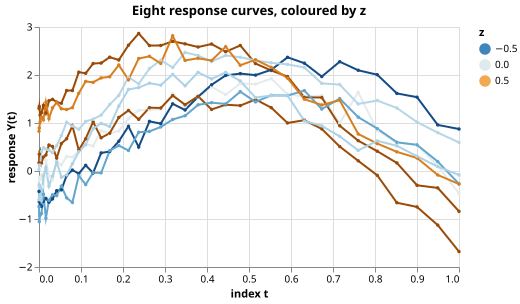

In [2]:
shown = np.arange(8)
sample_curves = pl.DataFrame({
    "t": np.tile(t, len(shown)),
    "Y": Y[shown].ravel(),
    "curve": np.repeat(shown, G),
    "z": np.repeat(z[shown], G),
})
alt.Chart(sample_curves).mark_line(point=alt.OverlayMarkDef(size=12)).encode(
    x=alt.X("t:Q", title="index t"),
    y=alt.Y("Y:Q", title="response Y(t)"),
    detail="curve:N",
    color=alt.Color("z:Q", scale=alt.Scale(scheme="blueorange"), title="z"),
).properties(title="Eight response curves, coloured by z", width=420, height=240)

The points show the grid: 20 of the 40 measurements lie below $t = 0.25$.
Curves with large $z$ start higher and end lower, which is the shape of
$z\,\beta_1(t)$ with $\beta_1(t) = \cos(\pi t)$.

## Stacking curves into rows

`gamboost` treats each row of the data as one observation. A curve therefore
becomes $G$ rows, one per index value, and every row of curve $i$ carries the
curve's identifier and its scalar covariates. This is called the long format.
The covariate is centred, $z_i - \bar z$, so that the term for $z$ sums to zero
over the curves at every index value and the functional intercept carries the
mean curve.

In [3]:
z_centred = z - z.mean()

long = pl.DataFrame({
    "curve": np.repeat(np.arange(N), G),   # which curve a row belongs to
    "t": np.tile(t, N),                    # index value of the measurement
    "z": np.repeat(z_centred, G),          # the curve's covariate, repeated
    "y": Y.ravel(),                        # row-major: curve 0's 40 values first
})
long.head(3)

curve,t,z,y
i64,f64,f64,f64
0,0.0,-0.052468,-0.323616
0,0.000657,-0.052468,-0.136199
0,0.00263,-0.052468,-0.164944


The frame has $N \cdot G$ = {eval}`long.height` rows. `Y.ravel()` reads the
matrix row by row, so the first 40 rows are curve 0, matching `np.repeat` for
the curve identifier and `np.tile` for the grid.

## Function-on-scalar model: bbs(t) and bols(z) %X% bbs(t)

The model $Y_i(t) = \beta_0(t) + z_i\,\beta_1(t) + \text{error}$ is written
with two terms:

- `bbs(t, df=4)` is the functional intercept $\beta_0(t)$: a smooth function of
  the index shared by all curves.
- `bols(z, intercept=False) %X% bbs(t, df=4)` is $z_i\,\beta_1(t)$. The row
  tensor product `%X%` multiplies the value of $z$ in each row by each B-spline
  of $t$, so the term's coefficients describe a smooth function of $t$ that
  multiplies $z$. See [](choosing_terms.ipynb) for `%X%` in general.

`intercept=False` and the centred $z$ together make the second term sum to
zero over the curves at every $t$: $\sum_i z_i\,\beta_1(t) = 0$ because
$\sum_i z_i = 0$. The intercept term then carries the mean curve and
$\beta_1(t)$ is a deviation from it. FDboost's `bolsc` imposes the same
constraint. Without it, `bols(z)` includes a constant column, the tensor
contains a second copy of the functional intercept, and the two terms divide
the mean curve between them in a way that depends on the path.

The degrees of freedom of a tensor term are the product of the degrees of
freedom of its two bases: `bols` without `df` counts as 1 and `bbs(t, df=4)` as 4, so both terms have 4. Equal degrees of
freedom give the two terms an equal chance of being selected at each step.

In [4]:
linear_formula = "y ~ bbs(t, df=4) + bols(z, intercept=False) %X% bbs(t, df=4)"
control = mb.boost_control(mstop=1000, nu=0.1)

fit = mb.gamboost(linear_formula, data=long, control=control)

## Curve-level cross-validation: grouped_folds

Measurements of one curve share its deviation $a_i + b_i \sin(2\pi t)$. Folds
drawn over rows put most measurements of a held-out curve in the training
data, so the held-out score measures how well the model fills gaps in curves it
has partly seen. The usual question is how well it predicts the curve of a new
unit. `grouped_folds` answers it by holding out whole curves: every row of a
curve falls in the same fold.

The cross-validation comparison scores two specifications on both fold designs, each with
five folds. The second specification, `bbs(z) %X% bbs(t)`, lets the effect of
$z$ be non-linear at every $t$; the true effect is linear. The last row is the
error of the true mean function $\beta_0(t) + z_i\,\beta_1(t)$ on the same data,
about the smallest error a model of the mean can expect on new curves.

In [5]:
flexible_formula = "y ~ bbs(t, df=4) + bbs(z, df=4) %X% bbs(t, df=4)"
fit_flexible = mb.gamboost(flexible_formula, data=long, control=control)

# Two fold designs over the same rows: rows at random, or whole curves.
row_folds = mb.cv_weights(long.height, "kfold", 5, seed=1)
curve_folds = mb.grouped_folds(long["curve"].to_numpy(), B=5, seed=1)

cv_rows = []
for label, model in (("bols(z) %X% bbs(t)", fit), ("bbs(z) %X% bbs(t)", fit_flexible)):
    for design, folds in (("rows", row_folds), ("curves", curve_folds)):
        curve = model.cvrisk(folds=folds)
        best = curve.optimal_mstop
        cv_rows.append({"effect of z": label, "folds": design,
                        "best mstop": best,
                        "held-out MSE": round(float(curve.aggregate[best]), 4)})

# The error of the true mean function on the same measurements.
true_mse = float(np.mean((Y - mean_curves) ** 2))
cv_rows.append({"effect of z": "true mean function", "folds": "",
                "best mstop": None, "held-out MSE": round(true_mse, 4)})
cv_table = pl.DataFrame(cv_rows)
cv_table

effect of z,folds,best mstop,held-out MSE
str,str,i64,f64
"""bols(z) %X% bbs(t)""","""rows""",133,0.1944
"""bols(z) %X% bbs(t)""","""curves""",103,0.2076
"""bbs(z) %X% bbs(t)""","""rows""",1000,0.1786
"""bbs(z) %X% bbs(t)""","""curves""",61,0.2088
"""true mean function""","""""",null,0.2031


In [6]:
# Values quoted in the text below.
def cv_value(effect, folds, column):
    row = cv_table.filter((pl.col("effect of z") == effect) & (pl.col("folds") == folds))
    return row[column][0]

flex_rows_mse = cv_value("bbs(z) %X% bbs(t)", "rows", "held-out MSE")
flex_rows_mstop = cv_value("bbs(z) %X% bbs(t)", "rows", "best mstop")
lin_rows_mse = cv_value("bols(z) %X% bbs(t)", "rows", "held-out MSE")
lin_curves_mse = cv_value("bols(z) %X% bbs(t)", "curves", "held-out MSE")
flex_curves_mse = cv_value("bbs(z) %X% bbs(t)", "curves", "held-out MSE")
best_mstop = cv_value("bols(z) %X% bbs(t)", "curves", "best mstop")

The held-out MSE is the mean squared error per measurement on the held-out
rows. On row folds the flexible model scores {eval}`flex_rows_mse` against
{eval}`lin_rows_mse` for the linear one, and its best step count is
{eval}`flex_rows_mstop`, the end of the path. Both row-fold scores are below
{eval}`round(true_mse, 4)`, the error of the true mean function, which a model
should not beat on new curves: the row folds reward a model for reproducing the
deviations $a_i$ and $b_i$ of curves whose other measurements it was trained on.
Because $z$ takes a different value on every curve, a flexible function of $z$
can do exactly that. On curve folds the linear model scores
{eval}`lin_curves_mse` and the flexible one {eval}`flex_curves_mse`: the fold
design that matches the prediction task chooses the true specification, and
row folds choose the other.

For stacked curves, every function that resamples must resample curves:
`cvrisk(folds=...)`, `stabsel(folds=...)` and the `folds=` argument of
`cv_risk`, `evaluate_specification` and `compare_specifications` all accept the
`FoldScheme` that `grouped_folds` returns, the object that assigns the rows
of each curve to one fold. The linear model is kept at the
curve-fold optimum, {eval}`best_mstop` steps.

In [7]:
fit = fit.with_mstop(best_mstop)

## Coefficient functions: β0(t) and β1(t)

For a model that is linear in $z$, the coefficient functions are differences of
predictions. At $z = 0$ (the mean of $z$, since $z$ is centred) the prediction
is $\beta_0(t)$; one unit higher it is $\beta_0(t) + \beta_1(t)$. Predicting
both on a fine grid of $t$ gives the two functions.

In [8]:
grid = np.linspace(0, 1, 101)

at_mean = np.asarray(fit.predict(newdata={"t": grid, "z": np.zeros_like(grid)})).ravel()
one_up = np.asarray(fit.predict(newdata={"t": grid, "z": np.ones_like(grid)})).ravel()

beta0_hat = at_mean
beta1_hat = one_up - at_mean

# The true beta0 is 2 sin(pi t) plus the mean of z times cos(pi t),
# because z was centred before fitting.
beta0_on_grid = 2 * np.sin(np.pi * grid) + z.mean() * np.cos(np.pi * grid)
beta1_on_grid = np.cos(np.pi * grid)
max_error_b0 = float(np.max(np.abs(beta0_hat - beta0_on_grid)))
max_error_b1 = float(np.max(np.abs(beta1_hat - beta1_on_grid)))

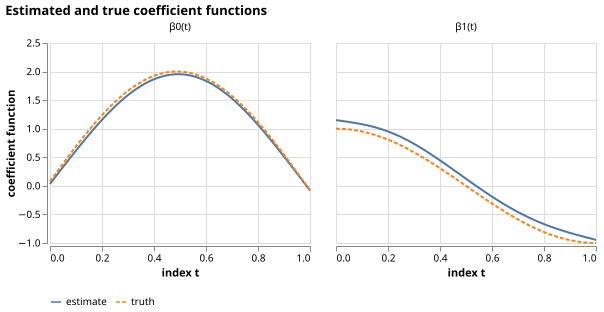

In [9]:
coefficients = pl.concat([
    pl.DataFrame({"t": grid, "value": beta0_hat, "series": "estimate", "function": "β0(t)"}),
    pl.DataFrame({"t": grid, "value": beta0_on_grid, "series": "truth", "function": "β0(t)"}),
    pl.DataFrame({"t": grid, "value": beta1_hat, "series": "estimate", "function": "β1(t)"}),
    pl.DataFrame({"t": grid, "value": beta1_on_grid, "series": "truth", "function": "β1(t)"}),
])
alt.Chart(coefficients).mark_line().encode(
    x=alt.X("t:Q", title="index t"),
    y=alt.Y("value:Q", title="coefficient function"),
    color=alt.Color("series:N", title=None, legend=alt.Legend(orient="bottom")),
    strokeDash=alt.StrokeDash("series:N", legend=None),
).properties(width=260, height=200).facet(
    column=alt.Column("function:N", title=None)
).properties(title="Estimated and true coefficient functions")

The largest absolute error over the grid is {eval}`round(max_error_b0, 3)` for
$\beta_0(t)$ and {eval}`round(max_error_b1, 3)` for $\beta_1(t)$. Part of the
error in $\beta_1(t)$ is shrinkage: boosting stopped early pulls the
coefficients towards zero, and 80 curves carry 80 values of $z$, not 3,200.

## Integration weights: weights=

Each measurement contributes equally to the loss, so the half of the grid below
$t = 0.25$ carries half the weight although it covers a quarter of the index.
When the loss should approximate an integral over $t$, weight each measurement
by the length of index it represents: half the distance to its neighbours
(the trapezoid rule). Those weights are passed through `weights=`.

In [10]:
# Trapezoid weights: each grid point stands for half the gap on each side.
gaps = np.diff(t)
trapezoid = np.concatenate([[gaps[0] / 2], (gaps[:-1] + gaps[1:]) / 2, [gaps[-1] / 2]])
row_weights = np.tile(trapezoid, N)

fit_weighted = mb.gamboost(linear_formula, data=long, weights=row_weights, control=control)
cv_weighted = fit_weighted.cvrisk(folds=curve_folds)
fit_weighted = fit_weighted.with_mstop(cv_weighted.optimal_mstop)

one_up_w = np.asarray(fit_weighted.predict(newdata={"t": grid, "z": np.ones_like(grid)})).ravel()
at_mean_w = np.asarray(fit_weighted.predict(newdata={"t": grid, "z": np.zeros_like(grid)})).ravel()
beta1_weighted = one_up_w - at_mean_w
weighted_change = float(np.max(np.abs(beta1_weighted - beta1_hat)))
weight_ratio = float(trapezoid.max() / trapezoid.min())

The weights range over a factor of {eval}`round(weight_ratio)` from the densest
to the sparsest part of the grid. The weighted fit, tuned on the same curve
folds at {eval}`cv_weighted.optimal_mstop` steps, changes $\hat\beta_1(t)$ by at
most {eval}`round(weighted_change, 3)`. The change is small here because the
model is correctly specified: both losses are minimized by the same mean
function. When the model is an approximation, the weights decide where along
the index the approximation is best. `cvrisk` multiplies each fold's weights by
the model's weights and weights the held-out error by them, so the
cross-validated error is also an integral over $t$. Fractional weights are
rescaled to sum to the number of rows, as in R's mboost; the ratios between
weights, which are what matter, are unchanged.

## Uncertainty: confint(groups=)

`confint` refits the model on bootstrap samples and reports quantiles of a
term's effect. By default a sample draws rows, which on stacked data treats the
40 measurements of a curve as 40 independent observations. `groups="curve"`
makes every sample draw whole curves with replacement; a row's weight in a
sample is the number of times its curve was drawn. With `B_mstop=5` the
number of boosting steps is re-tuned in every bootstrap sample, by an inner
resampling with five bootstrap folds that also draw whole curves.
At $z = 1$ the tensor term's effect is $\beta_1(t)$, so evaluating it on the
grid with $z = 1$ gives a band for $\beta_1(t)$.

In [11]:
tensor = "bols(z, intercept=False) %X% bbs(t, df=4)"
at_z_one = {"t": grid, "z": np.ones_like(grid)}

by_curve = fit.confint(parm=tensor, newdata=at_z_one, groups="curve",
                       B=100, B_mstop=5, level=0.9, seed=7)
by_row = fit.confint(parm=tensor, newdata=at_z_one,
                     B=100, B_mstop=5, level=0.9, seed=7)

lower, upper = by_curve["lower"][tensor], by_curve["upper"][tensor]
covered = float(np.mean((beta1_on_grid >= lower) & (beta1_on_grid <= upper)))
width_curves = float(np.mean(upper - lower))
width_rows = float(np.mean(by_row["upper"][tensor] - by_row["lower"][tensor]))

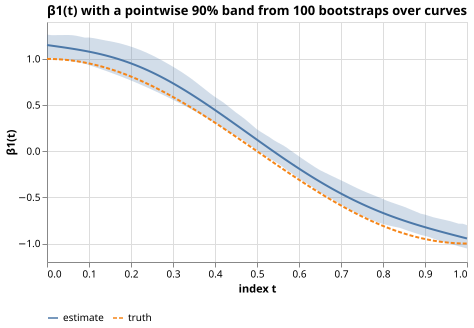

In [12]:
band = pl.DataFrame({"t": grid, "lower": lower, "upper": upper})
lines = pl.concat([
    pl.DataFrame({"t": grid, "value": beta1_hat, "series": "estimate"}),
    pl.DataFrame({"t": grid, "value": beta1_on_grid, "series": "truth"}),
])
area = alt.Chart(band).mark_area(opacity=0.25).encode(
    x=alt.X("t:Q", title="index t"), y=alt.Y("lower:Q", title="β1(t)"), y2="upper:Q")
curves = alt.Chart(lines).mark_line().encode(
    x="t:Q", y="value:Q",
    color=alt.Color("series:N", title=None, legend=alt.Legend(orient="bottom")),
    strokeDash=alt.StrokeDash("series:N", legend=None))
(area + curves).properties(
    title="β1(t) with a pointwise 90% band from 100 bootstraps over curves",
    width=420, height=240)

In [13]:
# In a simulation the curve levels a_i are known: their least-squares slope
# on z is the part of the estimated beta1 that this sample's levels explain.
level_shift = float(np.cov(z_centred, a)[0, 1] / np.var(z_centred, ddof=1))
mean_offset = float(np.mean(beta1_hat - beta1_on_grid))

Averaged over the grid, the band is {eval}`round(width_curves, 3)` wide. The
same call without `groups=` gives {eval}`round(width_rows, 3)`: resampling rows
understates the uncertainty because it ignores that a curve's measurements
share its deviation.

The band contains the true $\beta_1(t)$ at only {eval}`round(100 * covered)`% of
the 101 grid points. The estimate lies above the truth by about the same amount
along the whole index, on average {eval}`round(mean_offset, 3)`. The cause is in
this sample: the curve levels $a_i$ happen to be correlated with $z$, and the
least-squares slope of $a_i$ on $z$ is {eval}`round(level_shift, 3)`. A curve's
level enters every one of its measurements, so this error is shared by every
$t$, and a pointwise band on one data set tends either to contain the whole
function or to miss long stretches of it. A coverage check of the curve bootstrap repeats the bootstrap on 20 new data sets from the same
process to estimate its average coverage.

Two further properties limit how the band can be read. It is pointwise: each
vertical slice is a 90% interval for $\beta_1$ at that $t$, not a band that
contains the whole function with probability 0.9. And the estimates it
summarizes are shrunk towards zero by early stopping, and the band is too.

### Extension: coverage of the curve bootstrap

The question is whether the low coverage on the main data set is a property
of the method or of that data set. Each of 20 new data sets is drawn from the same
process and fitted with the same formula, and `confint(groups="curve",
B_mstop=5)` with 40 bootstrap samples gives a pointwise 90% band. The figure
shows, per data set, the share of grid points whose true $\beta_1(t)$ the band
contains; the dashed line is the nominal 0.9.

In [14]:
# One data set from the generating process above, in long format.
def simulate_curves(seed):
    sim = np.random.default_rng(seed)
    z_sim = sim.uniform(-1, 1, N)
    level, wave = sim.normal(0, 0.4, N), sim.normal(0, 0.3, N)
    Y_sim = (beta0_true + np.outer(z_sim, beta1_true) + level[:, None]
             + np.outer(wave, np.sin(2 * np.pi * t)) + sim.normal(0, 0.15, (N, G)))
    return pl.DataFrame({"curve": np.repeat(np.arange(N), G), "t": np.tile(t, N),
                         "z": np.repeat(z_sim - z_sim.mean(), G), "y": Y_sim.ravel()})

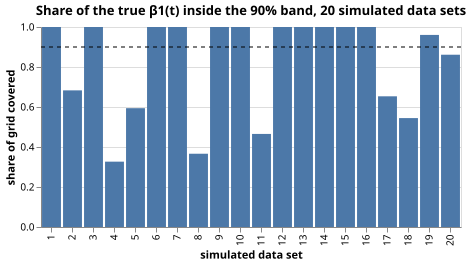

In [15]:
coverage_rows = []
for seed in range(100, 120):
    sim_fit = mb.gamboost(linear_formula, data=simulate_curves(seed), control=control)
    # The step count is tuned inside every bootstrap sample (B_mstop).
    band = sim_fit.confint(parm=tensor, newdata=at_z_one, groups="curve",
                           B=40, B_mstop=5, level=0.9, seed=seed)
    inside = (beta1_on_grid >= band["lower"][tensor]) & (beta1_on_grid <= band["upper"][tensor])
    coverage_rows.append({"data set": seed - 99, "share covered": float(np.mean(inside))})

coverage = pl.DataFrame(coverage_rows)
average_coverage = float(coverage["share covered"].mean())
full_cover = int(coverage.filter(pl.col("share covered") >= 0.95).height)
partial = coverage.filter(pl.col("share covered") < 0.95)["share covered"]

bars = alt.Chart(coverage).mark_bar().encode(
    x=alt.X("data set:O", title="simulated data set"),
    y=alt.Y("share covered:Q", title="share of grid covered", scale=alt.Scale(domain=[0, 1])))
nominal = alt.Chart(pl.DataFrame({"level": [0.9]})).mark_rule(strokeDash=[4, 4]).encode(y="level:Q")
(bars + nominal).properties(
    title="Share of the true β1(t) inside the 90% band, 20 simulated data sets",
    width=420, height=200)

Averaged over the 20 data sets, the band contains the true $\beta_1(t)$ at
{eval}`round(100 * average_coverage)`% of the grid points, below the nominal
90%. On {eval}`full_cover` data sets it contains the function at more than 95%
of the grid; on the others it misses a stretch of the index and covers between
{eval}`round(100 * partial.min())`% and {eval}`round(100 * partial.max())`% of it.
Misses come in stretches because each curve's level error is shared along $t$;
the data set in the Uncertainty section, at {eval}`round(100 * covered)`%, is an example. The
shortfall of the average is in the direction shrinkage predicts: early stopping
pulls every replicate's estimate towards zero, and the band with it. The
band indicates sampling variability and is not a calibrated interval. On
that data set the curve-level band is {eval}`round(width_curves / width_rows, 1)` times as
wide as the row bootstrap's band, and that difference is the error the
curve-level resampling removes.

## Scalar response, curve covariate: signal regression with buser

Each unit also has a covariate curve $x_i(s)$ recorded at 101 equally spaced
points of its own index $s \in [0, 1]$ (for example a spectrum over
wavelength), and a scalar response $r_i$. The model is

$$
r_i = \alpha + \int_0^1 x_i(s)\,\gamma(s)\,ds + e_i ,
$$

with a smooth coefficient function $\gamma(s)$. Writing
$\gamma(s) = \sum_k \theta_k B_k(s)$ in a B-spline basis turns the integral
into $\sum_k \theta_k \int x_i(s) B_k(s)\,ds$, which the trapezoid rule
approximates by $\sum_k \theta_k \sum_g w_g\, x_i(s_g) B_k(s_g)$. The model is
therefore linear in $\theta$ with design matrix $D = X\,W\,B$: the curves $X$
($N \times 101$), the diagonal matrix of trapezoid weights $W$, and the basis
$B$ evaluated on the grid ($101 \times K$). A difference penalty on $\theta$
makes $\gamma$ smooth. `learner_design` returns $B$ and the penalty of a `bbs`
term, and `buser` fits the resulting design.

The covariate curves are generated as random combinations of six bumps, plus
a little noise, and $\gamma(s) = 2 \sin(2\pi s)$.

In [16]:
s = np.linspace(0, 1, 101)
bumps = np.stack([np.exp(-((s - c) / 0.08) ** 2) for c in (0.15, 0.3, 0.45, 0.6, 0.75, 0.9)])
X_curves = rng.normal(size=(N, 6)) @ bumps + rng.normal(0, 0.02, (N, len(s)))

gamma_true = 2 * np.sin(2 * np.pi * s)
s_weights = np.full(len(s), s[1] - s[0])
s_weights[[0, -1]] /= 2                              # trapezoid rule on an even grid
r = X_curves @ (s_weights * gamma_true) + rng.normal(0, 0.2, N)

In [17]:
# Centre each grid column, so alpha is the mean response.
x_mean = X_curves.mean(axis=0)
X_centred = X_curves - x_mean

basis = mb.learner_design("bbs(s, knots=20, df=4)", {"s": s})
B, penalty = basis.design, basis.penalty
D = X_centred @ (s_weights[:, None] * B)             # the design X W B

units = {"r": r, "signal": np.zeros(N)}              # "signal" names the buser term
signal_fit = mb.gamboost("r ~ buser(signal, X=D, K=P, df=4)", data=units,
                         env={"D": D, "P": penalty},
                         control=mb.boost_control(mstop=2000, nu=0.1))
signal_cv = signal_fit.cvrisk(folds=mb.cv_weights(N, "kfold", 10, seed=1))
signal_fit = signal_fit.with_mstop(signal_cv.optimal_mstop)
D.shape

(80, 24)

Each unit is one row here, so ordinary ten-fold cross-validation is the right
fold design; it chose {eval}`signal_cv.optimal_mstop` steps. The estimated
coefficient function is $\hat\gamma(s) = B\hat\theta$, where $\hat\theta$ is the
term's coefficient vector from `coef()`.

In [18]:
theta_hat = signal_fit.coef()["signal"]
gamma_hat = B @ theta_hat
gamma_corr = float(np.corrcoef(gamma_hat, gamma_true)[0, 1])

pl.DataFrame({"statistic": ["correlation of estimated and true gamma(s)",
                            "largest absolute error in gamma(s)"],
              "value": [round(gamma_corr, 3),
                        round(float(np.max(np.abs(gamma_hat - gamma_true))), 3)]})

statistic,value
str,f64
"""correlation of estimated and t…",0.971
"""largest absolute error in gamm…",1.24


## Identifiability of γ(s)

The data determine $\gamma(s)$ only through the integrals
$\int x_i(s)\gamma(s)\,ds$. When the covariate curves vary in only a few
directions, many functions $\gamma$ give the same integrals, and the penalty,
not the data, chooses among them. The singular values of the design $D$ show
how many directions the data resolve.

In [19]:
singular = np.linalg.svd(D, compute_uv=False)
relative = singular / singular[0]
resolved = int(np.sum(relative > 0.05))
pl.DataFrame({"component": np.arange(1, 11), "relative singular value": np.round(relative[:10], 4)})

component,relative singular value
i64,f64
1,1.0
2,0.9418
3,0.8721
4,0.7664
5,0.7007
6,0.6024
7,0.0054
8,0.0044
9,0.0042


{eval}`resolved` singular values are large and the rest are below 0.01 of the
first: the curves were built from six bumps, so the data resolve six
directions of $\theta$ out of {eval}`D.shape[1]`. Along the others the fit is
decided by the penalty. A refit with `df=8`, a weaker penalty, is compared with the `df=4` fit on
its predictions and its coefficient function.

In [20]:
loose_fit = mb.gamboost("r ~ buser(signal, X=D, K=P, df=8)", data=units,
                        env={"D": D, "P": penalty},
                        control=mb.boost_control(mstop=2000, nu=0.1))
loose_cv = loose_fit.cvrisk(folds=mb.cv_weights(N, "kfold", 10, seed=1))
loose_fit = loose_fit.with_mstop(loose_cv.optimal_mstop)
gamma_loose = B @ loose_fit.coef()["signal"]

true_integrals = X_centred @ (s_weights * gamma_true)
rows = []
for label, model, g_hat, cv in (("df=4", signal_fit, gamma_hat, signal_cv),
                                ("df=8", loose_fit, gamma_loose, loose_cv)):
    fitted = D @ model.coef()["signal"]
    rows.append({"fit": label,
                 "CV MSE": round(float(cv.aggregate[cv.optimal_mstop]), 4),
                 "corr(fitted integral, true)": round(float(np.corrcoef(fitted, true_integrals)[0, 1]), 4),
                 "corr(estimate, gamma)": round(float(np.corrcoef(g_hat, gamma_true)[0, 1]), 3),
                 "largest absolute error": round(float(np.max(np.abs(g_hat - gamma_true))), 2)})
identifiability = pl.DataFrame(rows)
identifiability

fit,CV MSE,"corr(fitted integral, true)","corr(estimate, gamma)",largest absolute error
str,f64,f64,f64,f64
"""df=4""",0.0364,0.9895,0.971,1.24
"""df=8""",0.0368,0.9865,0.089,85.43


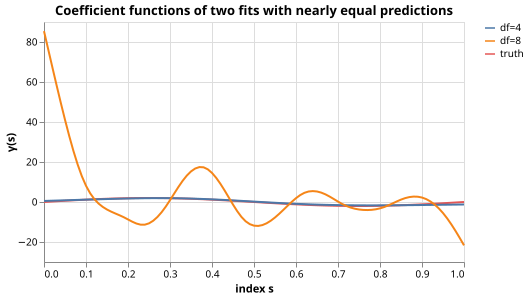

In [21]:
shapes = pl.concat([
    pl.DataFrame({"s": s, "value": gamma_true, "series": "truth"}),
    pl.DataFrame({"s": s, "value": gamma_hat, "series": "df=4"}),
    pl.DataFrame({"s": s, "value": gamma_loose, "series": "df=8"}),
])
alt.Chart(shapes).mark_line().encode(
    x=alt.X("s:Q", title="index s"),
    y=alt.Y("value:Q", title="γ(s)"),
    color=alt.Color("series:N", title=None),
).properties(title="Coefficient functions of two fits with nearly equal predictions",
             width=420, height=240)

The two fits predict almost equally well: their cross-validated errors differ
in the third decimal, and both sets of fitted integrals correlate with the true
integrals at about 0.99. Their coefficient functions do not agree: the weaker penalty lets $\hat\gamma(s)$ move freely along the
directions the data do not resolve. Before reading $\hat\gamma(s)$ as a shape,
check the singular values of $D$. When only a few are large, report the
predictions or the integrals, keep the penalty strong (a low `df`), and treat
the detailed shape of $\hat\gamma(s)$ as a product of the penalty.

## Prediction for new units

A new unit's curve is centred with the training means `x_mean` and turned into a
design row with the same weights and basis. `buser_newdata` passes that row to
the term, keyed by the term's column name.

In [22]:
new_curves = rng.normal(size=(3, 6)) @ bumps
new_design = (new_curves - x_mean) @ (s_weights[:, None] * B)

predicted = np.asarray(signal_fit.predict(newdata={"signal": np.zeros(3)},
                                          buser_newdata={"signal": new_design})).ravel()
mean_response = new_curves @ (s_weights * gamma_true)
pl.DataFrame({"unit": [1, 2, 3],
              "predicted r": np.round(predicted, 3),
              "true mean of r": np.round(mean_response, 3)})

unit,predicted r,true mean of r
i64,f64,f64
1,0.383,0.42
2,0.389,0.346
3,0.921,0.948


## Limitations

- Stacking multiplies the rows by the number of grid points, and a tensor term
  builds its full design: $N G$ rows by $p_1 p_2$ columns. With 1,000 curves on
  200 points and $24 \times 24$ splines that is 115 million values, about
  0.9 GB, for one term. FDboost avoids building this matrix for curves on a
  common grid.
- The centring that makes `bols(z, intercept=False) %X% bbs(t)` a deviation from
  the mean curve has no counterpart for a non-linear effect: the spline basis of
  `bbs(z)` contains the constant function, so `bbs(z) %X% bbs(t)` absorbs part of
  the mean curve. To read such a term, subtract its mean over the curves at each
  $t$ from its predictions.
- Every resampling call must resample curves: pass `folds=` built by
  `grouped_folds` to `cvrisk`, `stabsel` and the specification assistants, and
  `groups=` to `confint`. Their defaults resample rows.
- Effects in which the response at $t$ depends on the covariate curve up to $t$
  (historical effects) or on the covariate at $t$ only (concurrent effects) can
  be written as `buser` designs, but are not shown here. FDboost provides them
  as `bhist` and `bconcurrent`.

See also [](base_learners.ipynb) for `buser` and the other base learners,
[](model_selection.ipynb) for fold designs, and the case study
[](../cases/buser.ipynb) for writing designs with `learner_design`.